In [1]:
# =====================================================
# APPLICATION 3: PALINDROME STRING RECOGNITION
# NPDA AND CFG IMPLEMENTATION
# =====================================================

# STEP 1: Define NPDA components

alphabet = {'a', 'b'}
initial_state = 'q0'
final_state = 'qf'

# STEP 2: Define CFG

grammar = {
    'S': ['aSa', 'bSb', 'a', 'b', 'ε']
}

# STEP 3: Implement NPDA using stack
# NPDA guesses the midpoint of the input.

def palindrome_pda(text, trace=True):

    if any(ch not in alphabet for ch in text):

        if trace:
            print("Invalid alphabet")
            print("Result: REJECTED")

        return "REJECTED"

    if trace:
        print("\nInput String:", repr(text))
        print("Initial State:", initial_state)

    # Try all possible midpoint positions
    for midpoint in range(len(text) + 1):

        # skip=0: even-length midpoint
        # skip=1: odd-length midpoint
        for skip in (0, 1):

            if midpoint + skip > len(text):
                continue

            stack = ['$']
            valid = True

            if trace:
                print("\nTrying midpoint:", midpoint,
                      "| Skipped middle symbols:", skip)

            # STEP 4: Push first half onto stack

            for symbol in text[:midpoint]:

                stack.append(symbol)

                if trace:
                    print("Push:", symbol,
                          "| Stack:", stack)

            # STEP 5: Skip middle symbol if odd length

            if trace and skip == 1:
                print("Skipping middle symbol:",
                      text[midpoint])

            # STEP 6: Match remaining symbols

            for symbol in text[midpoint + skip:]:

                if len(stack) > 1 and stack[-1] == symbol:

                    stack.pop()

                    if trace:
                        print("Match:", symbol,
                              "| Stack:", stack)

                else:
                    valid = False
                    break

            # STEP 7: Check acceptance

            if valid and stack == ['$']:

                if trace:
                    print("Final State:", final_state)
                    print("Result: ACCEPTED")

                return "ACCEPTED"

    if trace:
        print("Final State: qd")
        print("Result: REJECTED")

    return "REJECTED"


# STEP 8: Test cases

test_cases = [
    "aba",
    "abba",
    "a",
    "bb",
    "baab",
    "ab",
    "aab",
    "baba",
    "abcba",
    ""
]

print("PALINDROME RECOGNITION TEST RESULTS")
print("=" * 45)

for test in test_cases:
    print(repr(test), ":", palindrome_pda(test, False))


# STEP 9: Accept user input

user_input = input("\nEnter a string using a and b: ")
palindrome_pda(user_input)

PALINDROME RECOGNITION TEST RESULTS
'aba' : ACCEPTED
'abba' : ACCEPTED
'a' : ACCEPTED
'bb' : ACCEPTED
'baab' : ACCEPTED
'ab' : REJECTED
'aab' : REJECTED
'baba' : REJECTED
'abcba' : REJECTED
'' : ACCEPTED

Enter a string using a and b: laalaal
Invalid alphabet
Result: REJECTED


'REJECTED'

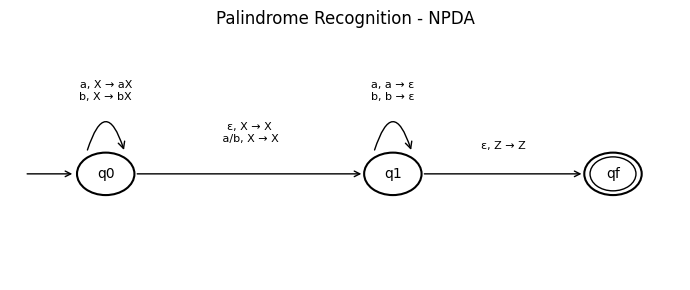

In [2]:
# PALINDROME RECOGNITION - NPDA DIAGRAM

import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch

fig, ax = plt.subplots(figsize=(7, 3))

ax.set_xlim(0, 7)
ax.set_ylim(0, 3.5)
ax.axis('off')

# STEP 1: Draw states

def draw_state(x, y, label, final=False):

    ax.add_patch(Circle((x, y), 0.30,
                        fill=False, linewidth=1.5))

    if final:
        ax.add_patch(Circle((x, y), 0.24,
                            fill=False, linewidth=1))

    ax.text(x, y, label, ha='center',
            va='center', fontsize=10)


draw_state(1, 1.5, 'q0')
draw_state(4, 1.5, 'q1')
draw_state(6.3, 1.5, 'qf', True)

# STEP 2: Initial arrow

ax.annotate('', xy=(0.68, 1.5), xytext=(0.15, 1.5),
            arrowprops=dict(arrowstyle='->'))

# STEP 3: Push first half onto stack

loop1 = FancyArrowPatch(
    (0.8, 1.8), (1.2, 1.8),
    connectionstyle="arc3,rad=-1.6",
    arrowstyle='->',
    mutation_scale=12
)

ax.add_patch(loop1)

ax.text(1, 2.55,
        'a, X → aX\nb, X → bX',
        ha='center', fontsize=8)

# STEP 4: Guess midpoint

ax.annotate('', xy=(3.7, 1.5), xytext=(1.3, 1.5),
            arrowprops=dict(arrowstyle='->'))

ax.text(2.5, 1.95,
        'ε, X → X\n a/b, X → X',
        ha='center', fontsize=8)

# STEP 5: Match and pop

loop2 = FancyArrowPatch(
    (3.8, 1.8), (4.2, 1.8),
    connectionstyle="arc3,rad=-1.6",
    arrowstyle='->',
    mutation_scale=12
)

ax.add_patch(loop2)

ax.text(4, 2.55,
        'a, a → ε\nb, b → ε',
        ha='center', fontsize=8)

# STEP 6: Accept when stack is empty

ax.annotate('', xy=(6, 1.5), xytext=(4.3, 1.5),
            arrowprops=dict(arrowstyle='->'))

ax.text(5.15, 1.85,
        'ε, Z → Z',
        ha='center', fontsize=8)

ax.set_title("Palindrome Recognition - NPDA", fontsize=12)

plt.tight_layout()
plt.show()

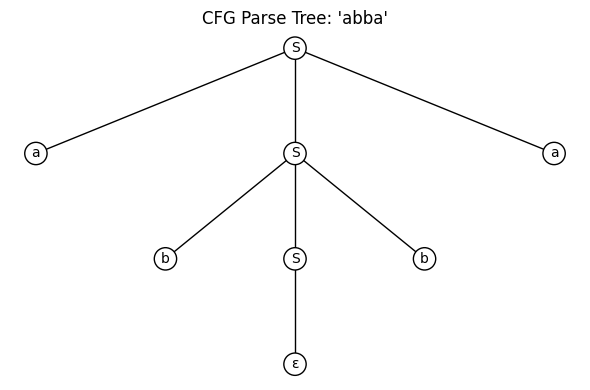

In [3]:
# PALINDROME RECOGNITION - CFG PARSE TREE

import matplotlib.pyplot as plt

def palindrome_tree(text):

    if palindrome_pda(text, False) != "ACCEPTED":
        print("Invalid palindrome. No parse tree.")
        return

    nodes = []
    edges = []

    # STEP 1: Build CFG derivation tree

    def build(s, parent=None):

        index = len(nodes)
        nodes.append("S")

        if parent is not None:
            edges.append((parent, index))

        if s == "":

            eps = len(nodes)
            nodes.append("ε")
            edges.append((index, eps))

        elif len(s) == 1:

            terminal = len(nodes)
            nodes.append(s)
            edges.append((index, terminal))

        else:

            left = len(nodes)
            nodes.append(s[0])
            edges.append((index, left))

            build(s[1:-1], index)

            right = len(nodes)
            nodes.append(s[-1])
            edges.append((index, right))

        return index

    build(text)

    # STEP 2: Calculate node levels

    levels = {}

    def assign_levels(node, level):

        levels[node] = level

        children = [b for a, b in edges if a == node]

        for child in children:
            assign_levels(child, level + 1)

    assign_levels(0, 0)

    # STEP 3: Calculate node positions

    positions = {}

    def place(node, x, width):

        positions[node] = (x, -levels[node])

        children = [b for a, b in edges if a == node]

        if children:

            gap = width / len(children)

            for i, child in enumerate(children):

                child_x = x - width/2 + gap*(i + 0.5)

                place(child, child_x, width/len(children)*1.5)

    place(0, 0, max(3, len(text) * 1.5))

    # STEP 4: Draw CFG parse tree

    fig, ax = plt.subplots(figsize=(6, 4))

    for a, b in edges:

        x1, y1 = positions[a]
        x2, y2 = positions[b]

        ax.plot([x1, x2], [y1, y2],
                'k-', linewidth=1)

    for i, label in enumerate(nodes):

        x, y = positions[i]

        ax.text(
            x, y, label,
            ha='center',
            va='center',
            fontsize=10,
            bbox=dict(boxstyle='circle',
                      fc='white', ec='black')
        )

    ax.set_title("CFG Parse Tree: " + repr(text))
    ax.axis('off')

    plt.tight_layout()
    plt.show()


palindrome_tree("abba")